# Módulo 3 — Extensión opcional: ERA5-Land real para Perú

**No evaluada, no obligatoria.** Pensada para el grupo que termine con margen
los Mini-desafíos del Día 5. Aplica exactamente las mismas funciones de `descarga.py` (Notebook 3)
a un caso nuevo: en vez del dominio del WRF (Argentina/Uruguay), el área que
cubre las 7 estaciones reales de Perú (`data/ogimet/coords_peru.json`), para
el mismo día que ya tiene observación real disponible (`data/obs/*_2024_12_13_horario.csv`).

**Por qué importa:** el dominio real del WRF de muestra (proyecto bigua) no
cubre Perú, así que nunca se puede validar el WRF contra una estación
peruana (ver Módulo 5, Día 8). Pero **ERA5-Land sí cubre Perú** — es un
producto global, no un dominio regional fijo como el WRF. Esta extensión
descarga ese insumo real, que se retoma en
[`05_extension_opcional_peru_addedvalue.ipynb`](../../modulo_05_validacion_resultados/notebooks/05_extension_opcional_peru_addedvalue.ipynb)
(Módulo 5, Día 9) para una comparación de *added value* distinta a la del
dominio del WRF: ERA5-Land (mayor resolución) vs. ERA5 de niveles de presión
(menor resolución), ambas contra la misma observación real.

## Descarga real (misma receta que `data/era_muestra/descarga_20241213.py`, otra área)

Mismo dataset (`reanalysis-era5-land`), mismas variables y mismo día que ya
se usó para el dominio del WRF — solo cambia `area`, acotada a las 7
estaciones de Perú en vez de a Argentina/Uruguay. Usa caché local: si el
archivo ya existe, no se vuelve a pedir al servidor.

In [1]:
import os
import cdsapi

RUTA_DESTINO = "../../../data/era_muestra/era5_land_peru_20241213.nc"

if os.path.exists(RUTA_DESTINO):
    print(f"Ya existe {RUTA_DESTINO}, no se vuelve a pedir al servidor.")
else:
    dataset = "reanalysis-era5-land"
    request = {
        "variable": [
            "2m_temperature",
            "10m_u_component_of_wind",
            "10m_v_component_of_wind",
            "total_precipitation",
        ],
        "year": "2024", "month": "12", "day": ["13"],
        "time": [f"{h:02d}:00" for h in range(24)],
        "data_format": "netcdf",
        "download_format": "unarchived",
        # [norte, oeste, sur, este] -- cubre Tumbes (-3.55) a Tacna (-18.05),
        # Piura (-80.6) a Cuzco (-71.9), con margen
        "area": [0, -82, -19, -68],
    }
    client = cdsapi.Client()
    client.retrieve(dataset, request, RUTA_DESTINO)
    print(f"Descarga real completada: {RUTA_DESTINO}")

Ya existe ../../../data/era_muestra/era5_land_peru_20241213.nc, no se vuelve a pedir al servidor.


## Verificación de integridad (reutilizando `descarga.py`, Notebook 3)

In [2]:
import sys
sys.path.insert(0, ".")
from descarga import verificar_integridad

ok, mensaje = verificar_integridad(RUTA_DESTINO, cobertura_esperada={"time_min_horas": 24})
print(ok, "-", mensaje)
assert ok, "La descarga no pasó la verificación -- revisar antes de usarla en el Módulo 5"

/home/japq/.conda/envs/jap/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True - OK


## Inspección rápida

Dimensiones: {'valid_time': 24, 'latitude': 191, 'longitude': 141}
Variables:   ['t2m', 'u10', 'v10', 'tp']


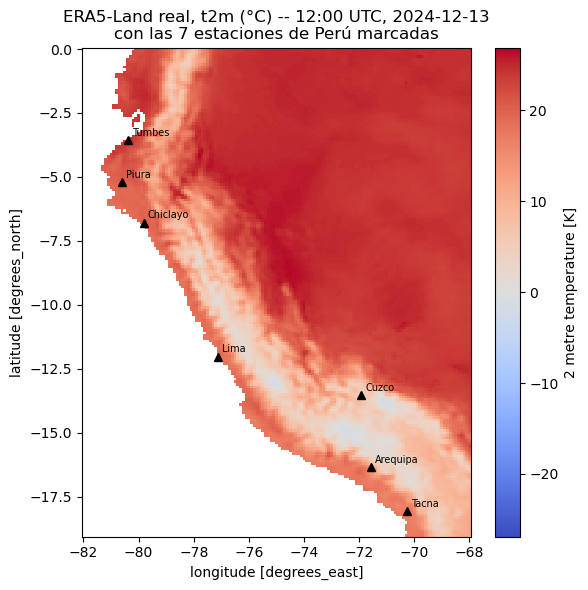

In [3]:
import json
import xarray as xr
import matplotlib.pyplot as plt

ds = xr.open_dataset(RUTA_DESTINO)
print("Dimensiones:", dict(ds.sizes))
print("Variables:  ", list(ds.data_vars))

coords_peru = json.load(open("../../../data/ogimet/coords_peru.json"))

fig, ax = plt.subplots(figsize=(6, 6))
(ds["t2m"].isel(valid_time=12) - 273.15).plot(ax=ax, cmap="coolwarm")
for nombre, c in coords_peru.items():
    ax.plot(c["lon"], c["lat"], "k^", markersize=6)
    ax.annotate(nombre, (c["lon"], c["lat"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_title("ERA5-Land real, t2m (°C) -- 12:00 UTC, 2024-12-13\ncon las 7 estaciones de Perú marcadas")
fig.tight_layout()
plt.show()

## Cierre

Entregable de esta extensión (si se completa): `era5_land_peru_20241213.nc`,
verificado. Se retoma en
[`05_extension_opcional_peru_addedvalue.ipynb`](../../modulo_05_validacion_resultados/notebooks/05_extension_opcional_peru_addedvalue.ipynb)
(Módulo 5, Día 9) para la comparación de *added value* con las 7 estaciones
reales de Perú.